In [1]:
import cv2
import numpy as np
import torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
from skimage.measure import regionprops, label
from skimage.color import rgb2gray
import scipy.ndimage as ndi
import math

# ---------- 1. SAM SETUP ----------
sam_checkpoint = "Checkpoints/sam_vit_h_4b8939.pth"  # path to SAM checkpoint
model_type = "vit_h"
device = "cuda" if torch.cuda.is_available() else "CPU"
print(f"Using device: {device}")
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=128,          # more points = finer segmentation (masks)
    pred_iou_thresh=0.7,          # lower = more mask candidates  
    stability_score_thresh=0.8,   # higher= filter out unstable masks/  lower = allow weaker masks
    min_mask_region_area=5      # ignore tiny regions
)


# ---------- 2. LOAD IMAGE ----------
img_bgr = cv2.imread("images/20250722_141557_1.jpg")   # Loads the input SEM/microscope image. (OpenCV loads images in BGR order)
if img_bgr is None:
    raise FileNotFoundError("composite_example.png not found")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)           # Converts it to RGB for SAM (which expects RGB).
gray = (rgb2gray(img_rgb) * 255).astype(np.uint8)            # Converts to grayscale for region intensity analysis.


# ---------- 3. GENERATE SAM MASKS ----------
masks = mask_generator.generate(img_rgb)
print(f"SAM produced {len(masks)} mask candidates") #Each mask is a dictionary with: "segmentation" → boolean mask "area", "bbox", "predicted_iou", etc.


# ---------- 4. EXTRACT REGION PROPERTIES ----------
# Converts each mask into labeled regions: SAM gives independent segmentation masks, but we need quantitative features — 
# e.g., area, brightness, shape — to tell whether each region is a fiber, void, or matrix.
# This block computes those features for every detected region.
# Example properties for a single region:
# p.area              # 1523 pixels
# p.bbox              # (100, 200, 150, 260) — bounding box coordinates
# p.centroid          # (125.3, 230.7) — center position
# p.perimeter         # 145.2 pixels
# p.mean_intensity    # 187.4 — average brightness inside the region
# p.max_intensity     # 255
# p.min_intensity     # 142
# p.eccentricity      # 0.85 — how elongated (0=circle, 1=line)
# p.orientation       # 1.23 radians — angle of elongation
# p.solidity          # 0.94 — how "solid" vs "holey"
# ... and many more
regions = []
for m in masks:
    bin_mask = m["segmentation"].astype(np.uint8)
    labeled = label(bin_mask)
    props = regionprops(labeled, intensity_image=gray)
    for p in props:
        if p.area < 5:  # skip tiny noise
            continue
        perim = p.perimeter if p.perimeter > 1e-8 else 1.0
        circularity = (4 * math.pi * p.area) / (perim**2 + 1e-8)  # Circularity is a shape metric: a perfect circle scores 1.0, a long thin fiber scores much lower.The tiny 1e-8 is added to prevent division by zero 
        regions.append({
            "mask": (labeled == p.label),
            "area": p.area,
            "mean_intensity": float(p.mean_intensity),
            "perimeter": p.perimeter,
            "circularity": circularity
        })

if len(regions) == 0:
    raise RuntimeError("No regions found. Adjust SAM settings or image preprocessing.")

# ---------- 5. AUTOMATIC THRESHOLD ESTIMATION ----------
areas = np.array([r["area"] for r in regions])
p50 = np.percentile(areas, 50)
fiber_area_max = max(10, p50)
void_area_min = fiber_area_max * 1.5

# Global intensity statistics
img_mean = gray.mean()
img_min, img_max = gray.min(), gray.max()
dark_threshold = img_mean - 0.3*(img_max - img_min)  # dynamic dark threshold
dark_fraction_threshold = 0.7

print("Estimated thresholds:")
print("fiber_area_max:", fiber_area_max)
print("void_area_min:", void_area_min)
print("dark_threshold:", dark_threshold)
print("image mean intensity:", img_mean)

# ---------- 6. INITIALIZE SEMANTIC MASK ----------
height, width = gray.shape
semantic_mask = np.zeros((height, width), dtype=np.uint8)  # 0=matrix,1=fiber,2=void

# ---------- 7. SORT REGIONS BY SIZE (LARGEST FIRST) ----------
regions_sorted = sorted(regions, key=lambda r: r["area"], reverse=True)

# ---------- 8. CLASSIFY REGIONS (RELATIVE INTENSITY) ----------
for r in regions_sorted:
    mask_bool = r["mask"]
    pixel_vals = gray[mask_bool]
    dark_fraction = np.sum(pixel_vals < dark_threshold) / len(pixel_vals)
    
    # Step 1: voids (large + dark)
    if r["area"] >= void_area_min and dark_fraction >= dark_fraction_threshold:
        label_id = 2  # void
    
   # Step 2: fibers (small + not dark)
    #elif r["area"] <= fiber_area_max * 1.4  and np.mean(pixel_vals) > dark_threshold:
        #label_id = 1  # fiber
        #else:
            #label_id = 0
    elif r["area"] <= fiber_area_max * 3:  # allow slightly larger
        # local adaptive test
        try:
            local_thresh = threshold_otsu(pixel_vals)
        except:
            local_thresh = img_mean
        if np.mean(pixel_vals) > local_thresh:
            label_id = 1  # fiber
        else:
            label_id = 0
    # Step 3: matrix
    else:
        label_id = 0


    # Paint label (only where mask not yet labeled)
    semantic_mask[np.logical_and(mask_bool, semantic_mask == 0)] = label_id

# ---------- 9. CLEANUP SMALL SPECKS ----------
for cls in (1, 2):
    cleaned = ndi.binary_opening(semantic_mask==cls, structure=np.ones((3,3)))
    cleaned = ndi.binary_fill_holes(cleaned)
    semantic_mask[semantic_mask==cls] = 0
    semantic_mask[cleaned] = cls

# ---------- 10. SAVE SEMANTIC MASK ----------
cv2.imwrite("composite_labeled_relative.png", semantic_mask)
print("Saved composite_labeled_relative.png (0=matrix,1=fiber,2=void)")

# ---------- 11. CREATE OVERLAY FOR VISUAL INSPECTION ----------
color_map = {
    0: [128,128,128],  # matrix = grey
    1: [255,255,255],  # fiber = white
    2: [0,0,0]         # void = black
}
color_mask = np.zeros((height, width, 3), dtype=np.uint8)
for k, col in color_map.items():
    color_mask[semantic_mask==k] = col

overlay = cv2.addWeighted(img_rgb, 0.6, color_mask, 0.4, 0)
cv2.imwrite("overlay_relative.png", cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
print("Saved overlay_relative.png for quick inspection")


Using device: cuda
SAM produced 700 mask candidates
Estimated thresholds:
fiber_area_max: 264.0
void_area_min: 396.0
dark_threshold: 63.34724444444444
image mean intensity: 123.34724444444444
Saved composite_labeled_relative.png (0=matrix,1=fiber,2=void)
Saved overlay_relative.png for quick inspection


image_rgb: (600, 600, 3)
semantic_mask: (600, 600)
✅ Saved individual images to /outputs folder


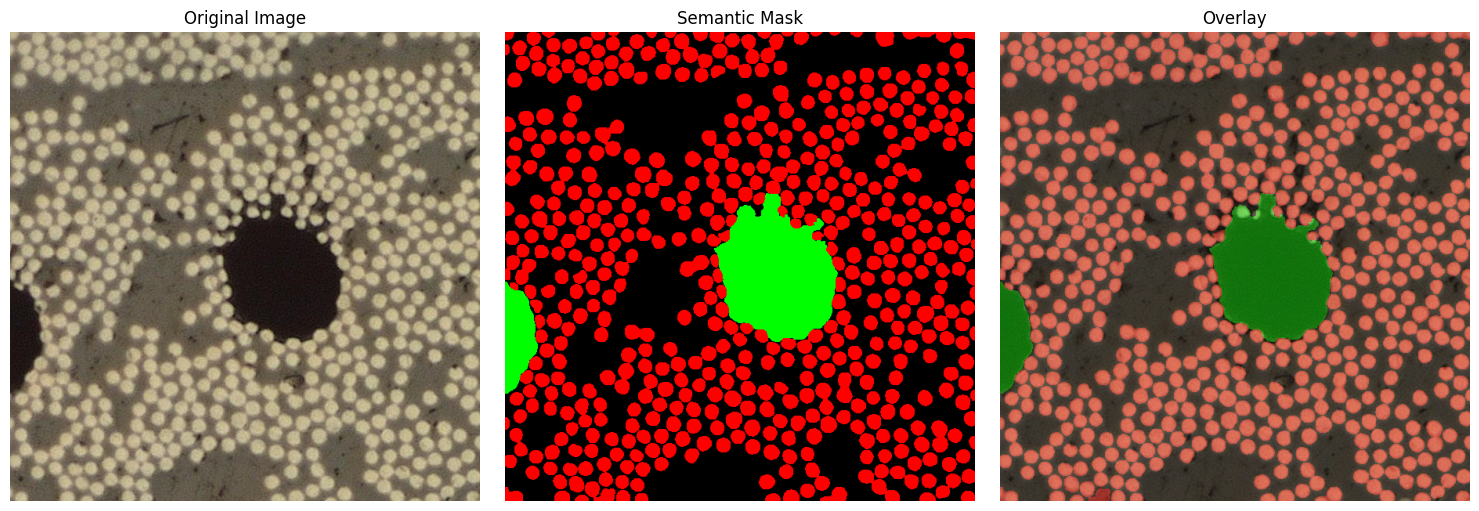

✅ Saved combined comparison: outputs/comparison_panel.png


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 1. Load original image ----------
image_path = "images/20250722_141557_1.jpg"
mask_path = "composite_labeled_relative.png"

image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

semantic_mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
if semantic_mask is None:
    raise FileNotFoundError(f"Mask not found: {mask_path}")

print("image_rgb:", image_rgb.shape)
print("semantic_mask:", semantic_mask.shape)

# ---------- 2. Define colors ----------
colors = {
    0: [0, 0, 0],         # matrix (black)
    1: [255, 0, 0],       # fibers (red)
    2: [0, 255, 0],       # voids (green)
}

# ---------- 3. Convert semantic mask to color mask ----------
color_mask = np.zeros((semantic_mask.shape[0], semantic_mask.shape[1], 3), dtype=np.uint8)
for class_id, color in colors.items():
    color_mask[semantic_mask == class_id] = color

# ---------- 4. Blend color mask with original image ----------
overlay = cv2.addWeighted(image_rgb, 0.6, color_mask, 0.4, 0)

# ---------- 5. Create output directory ----------
os.makedirs("outputs", exist_ok=True)

# ---------- 6. Save each image ----------
plt.imsave("outputs/original_image.png", image_rgb)
plt.imsave("outputs/semantic_mask.png", color_mask)
plt.imsave("outputs/overlay.png", overlay)
print("✅ Saved individual images to /outputs folder")

# ---------- 7. Display and save combined comparison ----------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(image_rgb)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Semantic Mask")
plt.imshow(color_mask)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Overlay")
plt.imshow(overlay)
plt.axis("off")

plt.tight_layout()
plt.savefig("outputs/comparison_panel.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Saved combined comparison: outputs/comparison_panel.png")


In [3]:
import cv2
import numpy as np
import torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
from skimage.measure import regionprops, label
from skimage.color import rgb2gray
from skimage.filters import threshold_otsu
import scipy.ndimage as ndi
import math

# ---------- 1. SAM SETUP ----------
sam_checkpoint = "Checkpoints/sam_vit_h_4b8939.pth"         # path to SAM checkpoint
model_type = "vit_h"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=128,          # more points = finer segmentation (masks)
    pred_iou_thresh=0.7,          # lower = more mask candidates  
    stability_score_thresh=0.8,   # higher= filter out unstable masks/  lower = allow weaker masks
    min_mask_region_area=5        # ignore tiny regions
)

# ---------- 2. LOAD IMAGE ----------
img_bgr = cv2.imread("images/20250722_141557_1.jpg")   # Loads the input SEM/microscope image. (OpenCV loads images in BGR order)
if img_bgr is None:
    raise FileNotFoundError("Image not found")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)           # Converts it to RGB for SAM (which expects RGB).
gray = (rgb2gray(img_rgb) * 255).astype(np.uint8)            # Converts to grayscale for region intensity analysis.


# ---------- 3. GENERATE SAM MASKS ----------
masks = mask_generator.generate(img_rgb)
print(f"SAM produced {len(masks)} mask candidates") #Each mask is a dictionary with: "segmentation" → boolean mask "area", "bbox", "predicted_iou", etc.

# ---------- 4. EXTRACT REGION PROPERTIES ----------
# Converts each mask into labeled regions: SAM gives independent segmentation masks, but we need quantitative features — 
# e.g., area, brightness, shape — to tell whether each region is a fiber, void, or matrix.
# This block computes those features for every detected region.
# Example properties for a single region:
# p.area              # 1523 pixels
# p.bbox              # (100, 200, 150, 260) — bounding box coordinates
# p.centroid          # (125.3, 230.7) — center position
# p.perimeter         # 145.2 pixels
# p.mean_intensity    # 187.4 — average brightness inside the region
# p.max_intensity     # 255
# p.min_intensity     # 142
# p.eccentricity      # 0.85 — how elongated (0=circle, 1=line)
# p.orientation       # 1.23 radians — angle of elongation
# p.solidity          # 0.94 — how "solid" vs "holey"
# ... and many more
regions = []
for m in masks:
    bin_mask = m["segmentation"].astype(np.uint8)
    labeled = label(bin_mask)
    props = regionprops(labeled, intensity_image=gray)
    for p in props:
        if p.area < 5: # skip tiny noise
            continue
        perim = p.perimeter if p.perimeter > 1e-8 else 1.0
        circularity = (4 * math.pi * p.area) / (perim**2 + 1e-8)  # Circularity is a shape metric: a perfect circle scores 1.0, a long thin fiber scores much lower.The tiny 1e-8 is added to prevent division by zero 
        regions.append({
            "mask": (labeled == p.label),
            "area": p.area,
            "mean_intensity": float(p.mean_intensity),
            "perimeter": p.perimeter,
            "circularity": circularity
        })

if len(regions) == 0:
    raise RuntimeError("No regions found. Adjust SAM settings or image preprocessing.")

# ---------- 5. THRESHOLD ESTIMATION ----------
areas = np.array([r["area"] for r in regions])
p50 = np.percentile(areas, 50)
fiber_area_max = max(10, p50)
void_area_min = fiber_area_max * 10

# FIX: use Otsu's method on the full grayscale image to find the natural
# valley between dark (matrix/void) and bright (fiber/bead) pixels.
# This is far more robust than min/max arithmetic, which gets skewed by
# the extreme dark pixels in voids pulling dark_threshold too low.
otsu_thresh = threshold_otsu(gray)

# dark_threshold sits halfway between 0 and the Otsu boundary —
# captures true void/matrix darkness without being fooled by mid-grey matrix
dark_threshold = otsu_thresh * 0.5

# fiber_threshold: a region must be brighter than Otsu to be called a fiber
fiber_brightness_threshold = otsu_thresh

img_mean = gray.mean()

print("Estimated thresholds:")
print("  fiber_area_max          :", fiber_area_max)
print("  void_area_min           :", void_area_min)
print("  otsu_thresh             :", otsu_thresh)
print("  dark_threshold (voids)  :", dark_threshold)
print("  fiber_brightness_thresh :", fiber_brightness_threshold)
print("  image mean              :", img_mean)

dark_fraction_threshold = 0.7

# ---------- 6. INITIALIZE SEMANTIC MASK ----------
height, width = gray.shape
semantic_mask = np.zeros((height, width), dtype=np.uint8)  # 0=matrix, 1=fiber, 2=void

# ---------- 7. SORT BY SIZE LARGEST FIRST ----------
regions_sorted = sorted(regions, key=lambda r: r["area"], reverse=True)

# ---------- 8. CLASSIFY REGIONS ----------
for r in regions_sorted:
    mask_bool = r["mask"]
    pixel_vals = gray[mask_bool]
    dark_fraction = np.sum(pixel_vals < dark_threshold) / len(pixel_vals)
    mean_val = np.mean(pixel_vals)

    # Void: large AND predominantly very dark
    if r["area"] >= void_area_min and dark_fraction >= dark_fraction_threshold:
        label_id = 2

    # Fiber: small AND circular AND brighter than Otsu threshold
    elif r["area"] <= fiber_area_max * 3:
        if r["circularity"] > 0.65 and mean_val > fiber_brightness_threshold:
            label_id = 1   # small + round + bright → fiber/bead
        else:
            label_id = 0   # small but dark or irregular → matrix

    # Matrix: everything else
    else:
        label_id = 0

    semantic_mask[np.logical_and(mask_bool, semantic_mask == 0)] = label_id

# ---------- 9. CLEANUP ----------
for cls in (1, 2):
    cleaned = ndi.binary_opening(semantic_mask == cls, structure=np.ones((3, 3)))
    cleaned = ndi.binary_fill_holes(cleaned)
    semantic_mask[semantic_mask == cls] = 0
    semantic_mask[cleaned] = cls

# ---------- 10. SAVE ----------
cv2.imwrite("composite_labeled_relative.png", semantic_mask)
print("Saved composite_labeled_relative.png  (0=matrix, 1=fiber, 2=void)")

# ---------- 11. OVERLAY ----------
color_map = {
    0: [128, 128, 128],
    1: [255, 255, 255],
    2: [0,   0,   0  ]
}
color_mask = np.zeros((height, width, 3), dtype=np.uint8)
for k, col in color_map.items():
    color_mask[semantic_mask == k] = col

overlay = cv2.addWeighted(img_rgb, 0.6, color_mask, 0.4, 0)
cv2.imwrite("overlay_relative.png", cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
print("Saved overlay_relative.png for quick inspection")

# ---------- 12. STATS ----------
total_px = height * width
for cls, name in [(0, "matrix"), (1, "fiber"), (2, "void")]:
    px = np.sum(semantic_mask == cls)
    print(f"  {name:8s}: {px:>10,} px  ({100*px/total_px:.1f}%)")

Using device: cuda
SAM produced 700 mask candidates
Estimated thresholds:
  fiber_area_max          : 264.0
  void_area_min           : 2640.0
  otsu_thresh             : 128
  dark_threshold (voids)  : 64.0
  fiber_brightness_thresh : 128
  image mean              : 123.34724444444444
Saved composite_labeled_relative.png  (0=matrix, 1=fiber, 2=void)
Saved overlay_relative.png for quick inspection
  matrix  :    193,012 px  (53.6%)
  fiber   :    143,052 px  (39.7%)
  void    :     23,936 px  (6.6%)


image_rgb: (600, 600, 3)
semantic_mask: (600, 600)
✅ Saved individual images to /outputs folder


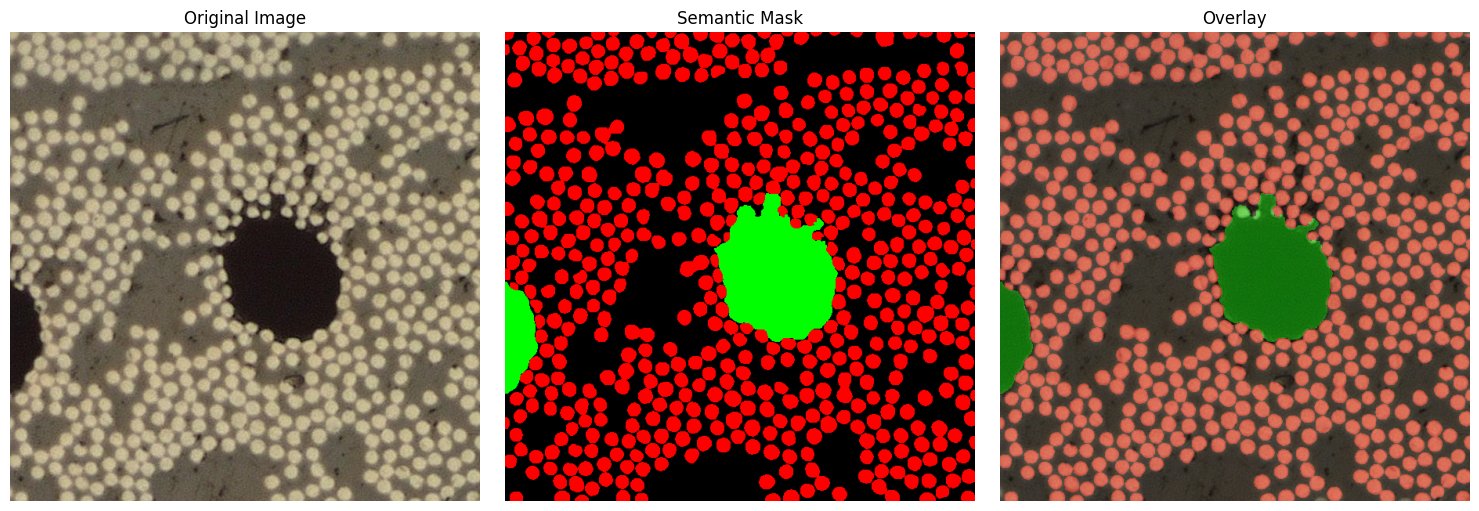

✅ Saved combined comparison: outputs/comparison_panel.png


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 1. Load original image ----------
image_path = "images/20250722_141557_1.jpg"
mask_path = "composite_labeled_relative.png"

image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

semantic_mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
if semantic_mask is None:
    raise FileNotFoundError(f"Mask not found: {mask_path}")

print("image_rgb:", image_rgb.shape)
print("semantic_mask:", semantic_mask.shape)

# ---------- 2. Define colors ----------
colors = {
    0: [0, 0, 0],         # matrix (black)
    1: [255, 0, 0],       # fibers (red)
    2: [0, 255, 0],       # voids (green)
}

# ---------- 3. Convert semantic mask to color mask ----------
color_mask = np.zeros((semantic_mask.shape[0], semantic_mask.shape[1], 3), dtype=np.uint8)
for class_id, color in colors.items():
    color_mask[semantic_mask == class_id] = color

# ---------- 4. Blend color mask with original image ----------
overlay = cv2.addWeighted(image_rgb, 0.6, color_mask, 0.4, 0)

# ---------- 5. Create output directory ----------
os.makedirs("outputs", exist_ok=True)

# ---------- 6. Save each image ----------
plt.imsave("outputs/original_image.png", image_rgb)
plt.imsave("outputs/semantic_mask.png", color_mask)
plt.imsave("outputs/overlay.png", overlay)
print("✅ Saved individual images to /outputs folder")

# ---------- 7. Display and save combined comparison ----------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(image_rgb)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Semantic Mask")
plt.imshow(color_mask)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Overlay")
plt.imshow(overlay)
plt.axis("off")

plt.tight_layout()
plt.savefig("outputs/comparison_panel.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Saved combined comparison: outputs/comparison_panel.png")


Classes:

🔴 Red = fibers

🟢 Green = voids

⚫ Black = matrix

dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])


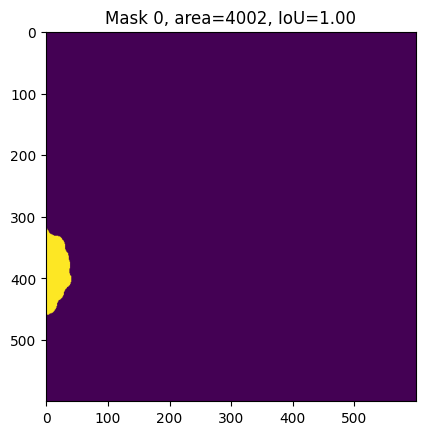

In [5]:
print(masks[0].keys())
import matplotlib.pyplot as plt
plt.imshow(masks[0]['segmentation'])
plt.title(f"Mask 0, area={masks[0]['area']}, IoU={masks[0]['predicted_iou']:.2f}")
plt.show() #predicted_iou= SAM’s confidence score (between 0 and 1), estimating how accurate the mask is.

In [3]:
import cv2
import numpy as np
import torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
from skimage.measure import regionprops, label
from skimage.color import rgb2gray
from skimage.filters import threshold_otsu
import scipy.ndimage as ndi
import math

# ---------- 1. SAM SETUP ----------
sam_checkpoint = "Checkpoints/sam_vit_h_4b8939.pth"         # path to SAM checkpoint
model_type = "vit_h"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=128,          # more points = finer segmentation (masks)
    pred_iou_thresh=0.7,          # lower = more mask candidates  
    stability_score_thresh=0.8,   # higher= filter out unstable masks/  lower = allow weaker masks
    min_mask_region_area=5        # ignore tiny regions
)

# ---------- 2. LOAD IMAGE ----------
img_bgr = cv2.imread("images/20250722_162144_1_X300_0.jpg")   # Loads the input SEM/microscope image. (OpenCV loads images in BGR order)
if img_bgr is None:
    raise FileNotFoundError("Image not found")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)           # Converts it to RGB for SAM (which expects RGB).
gray = (rgb2gray(img_rgb) * 255).astype(np.uint8)            # Converts to grayscale for region intensity analysis.


# ---------- 3. GENERATE SAM MASKS ----------
masks = mask_generator.generate(img_rgb)
print(f"SAM produced {len(masks)} mask candidates") #Each mask is a dictionary with: "segmentation" → boolean mask "area", "bbox", "predicted_iou", etc.

# ---------- 4. EXTRACT REGION PROPERTIES ----------
# Converts each mask into labeled regions: SAM gives independent segmentation masks, but we need quantitative features — 
# e.g., area, brightness, shape — to tell whether each region is a fiber, void, or matrix.
# This block computes those features for every detected region.
# Example properties for a single region:
# p.area              # 1523 pixels
# p.bbox              # (100, 200, 150, 260) — bounding box coordinates
# p.centroid          # (125.3, 230.7) — center position
# p.perimeter         # 145.2 pixels
# p.mean_intensity    # 187.4 — average brightness inside the region
# p.max_intensity     # 255
# p.min_intensity     # 142
# p.eccentricity      # 0.85 — how elongated (0=circle, 1=line)
# p.orientation       # 1.23 radians — angle of elongation
# p.solidity          # 0.94 — how "solid" vs "holey"
# ... and many more
regions = []
for m in masks:
    bin_mask = m["segmentation"].astype(np.uint8)
    labeled = label(bin_mask)
    props = regionprops(labeled, intensity_image=gray)
    for p in props:
        if p.area < 5: # skip tiny noise
            continue
        perim = p.perimeter if p.perimeter > 1e-8 else 1.0
        circularity = (4 * math.pi * p.area) / (perim**2 + 1e-8)  # Circularity is a shape metric: a perfect circle scores 1.0, a long thin fiber scores much lower.The tiny 1e-8 is added to prevent division by zero 
        regions.append({
            "mask": (labeled == p.label),
            "area": p.area,
            "mean_intensity": float(p.mean_intensity),
            "perimeter": p.perimeter,
            "circularity": circularity
        })

if len(regions) == 0:
    raise RuntimeError("No regions found. Adjust SAM settings or image preprocessing.")

# ---------- 5. THRESHOLD ESTIMATION ----------
areas = np.array([r["area"] for r in regions])
p50 = np.percentile(areas, 50)
fiber_area_max = max(10, p50)
void_area_min = fiber_area_max * 10

# FIX: use Otsu's method on the full grayscale image to find the natural
# valley between dark (matrix/void) and bright (fiber/bead) pixels.
# This is far more robust than min/max arithmetic, which gets skewed by
# the extreme dark pixels in voids pulling dark_threshold too low.
otsu_thresh = threshold_otsu(gray)

# dark_threshold sits halfway between 0 and the Otsu boundary —
# captures true void/matrix darkness without being fooled by mid-grey matrix
dark_threshold = otsu_thresh * 0.5

# fiber_threshold: a region must be brighter than Otsu to be called a fiber
fiber_brightness_threshold = otsu_thresh

img_mean = gray.mean()

print("Estimated thresholds:")
print("  fiber_area_max          :", fiber_area_max)
print("  void_area_min           :", void_area_min)
print("  otsu_thresh             :", otsu_thresh)
print("  dark_threshold (voids)  :", dark_threshold)
print("  fiber_brightness_thresh :", fiber_brightness_threshold)
print("  image mean              :", img_mean)

dark_fraction_threshold = 0.7

# ---------- 6. INITIALIZE SEMANTIC MASK ----------
height, width = gray.shape
semantic_mask = np.zeros((height, width), dtype=np.uint8)  # 0=matrix, 1=fiber, 2=void

# ---------- 7. SORT BY SIZE LARGEST FIRST ----------
regions_sorted = sorted(regions, key=lambda r: r["area"], reverse=True)

# ---------- 8. CLASSIFY REGIONS ----------
for r in regions_sorted:
    mask_bool = r["mask"]
    pixel_vals = gray[mask_bool]
    dark_fraction = np.sum(pixel_vals < dark_threshold) / len(pixel_vals)
    mean_val = np.mean(pixel_vals)

    # Void: large AND predominantly very dark
    if r["area"] >= void_area_min and dark_fraction >= dark_fraction_threshold:
        label_id = 2

    # Fiber: small AND circular AND brighter than Otsu threshold
    elif r["area"] <= fiber_area_max * 3:
        if r["circularity"] > 0.65 and mean_val > fiber_brightness_threshold:
            label_id = 1   # small + round + bright → fiber/bead
        else:
            label_id = 0   # small but dark or irregular → matrix

    # Matrix: everything else
    else:
        label_id = 0

    semantic_mask[np.logical_and(mask_bool, semantic_mask == 0)] = label_id

# ---------- 9. CLEANUP ----------
for cls in (1, 2):
    cleaned = ndi.binary_opening(semantic_mask == cls, structure=np.ones((3, 3)))
    cleaned = ndi.binary_fill_holes(cleaned)
    semantic_mask[semantic_mask == cls] = 0
    semantic_mask[cleaned] = cls

# ---------- 10. SAVE ----------
cv2.imwrite("composite_labeled_relative1.png", semantic_mask)
print("Saved composite_labeled_relative1.png  (0=matrix, 1=fiber, 2=void)")

# ---------- 11. OVERLAY ----------
color_map = {
    0: [128, 128, 128],
    1: [255, 255, 255],
    2: [0,   0,   0  ]
}
color_mask = np.zeros((height, width, 3), dtype=np.uint8)
for k, col in color_map.items():
    color_mask[semantic_mask == k] = col

overlay = cv2.addWeighted(img_rgb, 0.6, color_mask, 0.4, 0)
cv2.imwrite("overlay_relative1.png", cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
print("Saved overlay_relative1.png for quick inspection")

# ---------- 12. STATS ----------
total_px = height * width
for cls, name in [(0, "matrix"), (1, "fiber"), (2, "void")]:
    px = np.sum(semantic_mask == cls)
    print(f"  {name:8s}: {px:>10,} px  ({100*px/total_px:.1f}%)")

Using device: cuda
SAM produced 735 mask candidates
Estimated thresholds:
  fiber_area_max          : 270.0
  void_area_min           : 2700.0
  otsu_thresh             : 131
  dark_threshold (voids)  : 65.5
  fiber_brightness_thresh : 131
  image mean              : 130.8591277777778
Saved composite_labeled_relative1.png  (0=matrix, 1=fiber, 2=void)
Saved overlay_relative1.png for quick inspection
  matrix  :    140,621 px  (39.1%)
  fiber   :    156,178 px  (43.4%)
  void    :     63,201 px  (17.6%)


image_rgb: (600, 600, 3)
semantic_mask: (600, 600)
✅ Saved individual images to /outputs folder


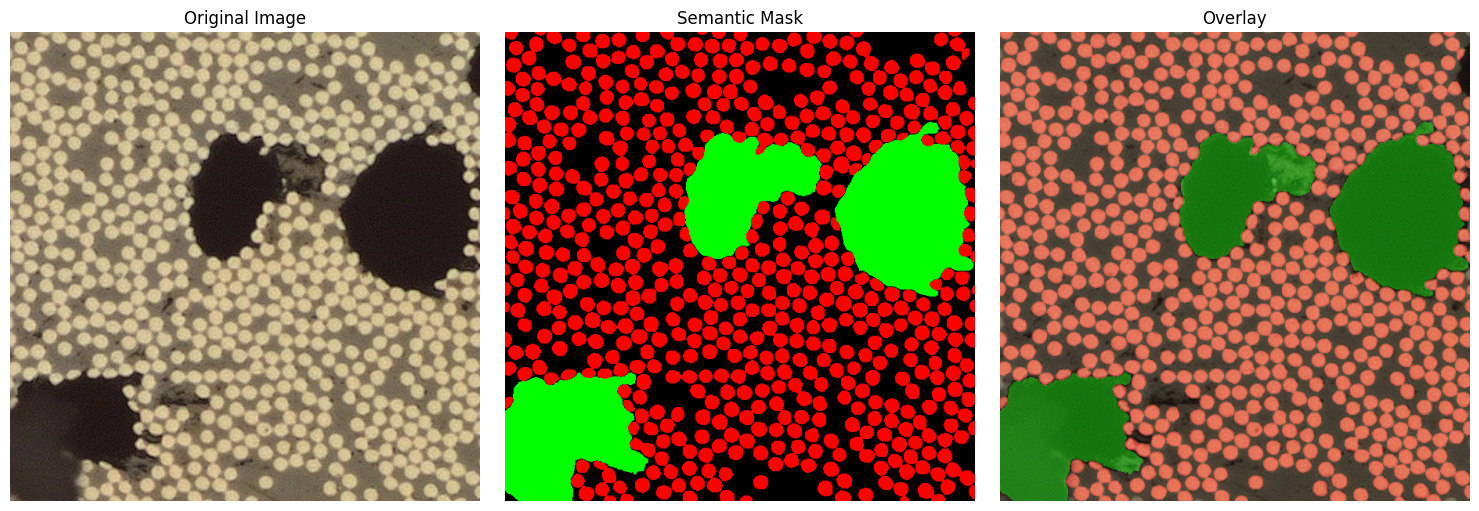

✅ Saved combined comparison: outputs/comparison_panel.png


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 1. Load original image ----------
image_path = "images/20250722_162144_1_X300_0.jpg"
mask_path = "composite_labeled_relative1.png"

image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

semantic_mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
if semantic_mask is None:
    raise FileNotFoundError(f"Mask not found: {mask_path}")

print("image_rgb:", image_rgb.shape)
print("semantic_mask:", semantic_mask.shape)

# ---------- 2. Define colors ----------
colors = {
    0: [0, 0, 0],         # matrix (black)
    1: [255, 0, 0],       # fibers (red)
    2: [0, 255, 0],       # voids (green)
}

# ---------- 3. Convert semantic mask to color mask ----------
color_mask = np.zeros((semantic_mask.shape[0], semantic_mask.shape[1], 3), dtype=np.uint8)
for class_id, color in colors.items():
    color_mask[semantic_mask == class_id] = color

# ---------- 4. Blend color mask with original image ----------
overlay = cv2.addWeighted(image_rgb, 0.6, color_mask, 0.4, 0)

# ---------- 5. Create output directory ----------
os.makedirs("outputs1", exist_ok=True)

# ---------- 6. Save each image ----------
plt.imsave("outputs1/original_image.png", image_rgb)
plt.imsave("outputs1/semantic_mask.png", color_mask)
plt.imsave("outputs1/overlay.png", overlay)
print("✅ Saved individual images to /outputs folder")

# ---------- 7. Display and save combined comparison ----------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(image_rgb)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Semantic Mask")
plt.imshow(color_mask)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Overlay")
plt.imshow(overlay)
plt.axis("off")

plt.tight_layout()
plt.savefig("outputs1/comparison_panel.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Saved combined comparison: outputs/comparison_panel.png")